# Three-Dimensional N-Body Simulation with a CUDA Octree

This notebook extends the direct and quadtree N-body examples to a three-dimensional Barnes–Hut simulation. The CUDA program builds a fixed-depth octree on the GPU, computes approximate forces by traversing it, and advances the particles with Velocity-Verlet. It also includes an exact tiled CUDA force kernel and CPU references for validation and timing.

The implementation favors a compact, regular data structure: every possible node is reserved in one array, Morton codes identify cells, and occupied leaves keep linked lists of their bodies. This avoids dynamic allocation and pointer chasing during construction. The root cube must contain the full trajectory. The notebook uses normalized units, a softening length, and a spherical cloud orbiting a massive central body.

Python creates reproducible initial-state files, plots the initial cloud, and saves the trajectory as a separate GIF. All force calculations, tree construction, and time integration are in CUDA C++. Use a recent CUDA Toolkit and an NVIDIA GPU with native double-precision atomicAdd support (compute capability 6.0 or newer).

## 1. Create reproducible 3D initial states

The same seed is used for the 512, 2048, and 8192 body cases. Each file contains a body count followed by position, mass, and velocity values as `float64`. The 512-body sample is used for validation and animation; the larger samples are used for timing.

In [1]:
from pathlib import Path
import numpy as np
import hashlib

random_seed = 42
central_mass = 100.0
disk_mass = 1.0

for body_count in (512, 2048, 8192):
    rng = np.random.default_rng(random_seed)
    state = np.zeros((body_count, 7), dtype=np.float64)
    state[0, 3] = central_mass

    # Sample points uniformly in volume within a spherical shell.
    direction = rng.normal(size=(body_count - 1, 3))
    direction /= np.linalg.norm(direction, axis=1)[:, None]
    radius = np.cbrt(rng.uniform(1.0, 64.0, body_count - 1))
    position = radius[:, None] * direction
    state[1:, :3] = position
    state[1:, 3] = disk_mass / (body_count - 1)

    # Choose a tangent velocity so each body begins on a circular orbit
    # around the central mass, neglecting the lighter cloud's self-gravity.
    reference = np.zeros_like(direction)
    use_x_axis = np.abs(direction[:, 2]) > 0.9
    reference[~use_x_axis, 2] = 1.0
    reference[use_x_axis, 0] = 1.0
    tangent = np.cross(reference, direction)
    tangent /= np.linalg.norm(tangent, axis=1)[:, None]
    speed = np.sqrt(central_mass / radius)
    state[1:, 4:7] = speed[:, None] * tangent

    path = Path(f"nbody_3d_{body_count}.bin")
    with path.open("wb") as file:
        np.asarray([body_count], dtype=np.uint64).tofile(file)
        state.tofile(file)
    print(f"Created {path}; SHA-256: {hashlib.sha256(path.read_bytes()).hexdigest()}")


Created nbody_3d_512.bin; SHA-256: 3bb17729ac89f39ab6dcdcc8ae421b1ef8169e212cc6b1ce35d3b3e32184d744
Created nbody_3d_2048.bin; SHA-256: e04c83a7958733bed1599b0e65e92cc2c77aceb51acfd759e2fc69ca637651a2
Created nbody_3d_8192.bin; SHA-256: 24ee387372e9fc9779b437172df3116529a88a7d8c3bfe9123bf5132d03c092a


## 2. CUDA implementation

The octree has six subdivision levels, or 64 cells along each coordinate and 262,144 possible leaves. Internal nodes store total mass and mass-weighted coordinates. The tree is rebuilt for each force evaluation because the particles move. The traversal uses the Barnes–Hut opening parameter `theta = 0.5`; cells containing the target are always opened.

In [2]:
%%writefile nbody_octree.cu
#include <cuda_runtime.h>

#include <algorithm>
#include <chrono>
#include <cmath>
#include <cstdint>
#include <cstdlib>
#include <fstream>
#include <iostream>
#include <vector>

constexpr int BLOCK_SIZE = 256;
// Six binary subdivisions per coordinate give a 64 x 64 x 64 leaf grid.
constexpr int TREE_DEPTH = 6;
constexpr int GRID_SIZE = 1 << TREE_DEPTH;
constexpr int LEAF_COUNT = 1 << (3 * TREE_DEPTH);
constexpr int NODE_COUNT = ((1 << (3 * (TREE_DEPTH + 1))) - 1) / 7;
constexpr double ROOT_MIN = -8.0;
constexpr double ROOT_SIZE = 16.0;
constexpr double G = 1.0;

#define CUDA_CHECK(call) do { \
    cudaError_t error = (call); \
    if (error != cudaSuccess) { \
        std::cerr << "CUDA error: " << cudaGetErrorString(error) \
                  << " at " << __FILE__ << ":" << __LINE__ << "\n"; \
        std::exit(EXIT_FAILURE); \
    } \
} while (0)

struct alignas(16) Record {
    double x, y, z, w;
};

struct HostState {
    std::vector<Record> position_mass;
    std::vector<Record> velocity;
};

HostState load_initial_conditions(const char* filename, int expected_n) {
    std::ifstream input(filename, std::ios::binary);
    std::uint64_t stored_n = 0;
    if (!input.read(reinterpret_cast<char*>(&stored_n), sizeof(stored_n)) ||
        stored_n != static_cast<std::uint64_t>(expected_n)) {
        std::cerr << "Initial-condition file is missing or has the wrong body count.\n";
        std::exit(EXIT_FAILURE);
    }
    HostState state;
    state.position_mass.resize(expected_n);
    state.velocity.resize(expected_n);
    for (int i = 0; i < expected_n; ++i) {
        double v[7];
        if (!input.read(reinterpret_cast<char*>(v), sizeof(v))) {
            std::cerr << "Initial-condition file is incomplete.\n";
            std::exit(EXIT_FAILURE);
        }
        state.position_mass[i] = {v[0], v[1], v[2], v[3]};
        state.velocity[i] = {v[4], v[5], v[6], 0.0};
    }
    return state;
}

__host__ __device__ inline int level_offset(int level) {
    return ((1 << (3 * level)) - 1) / 7;
}

__host__ __device__ inline unsigned int spread_3bits(unsigned int v) {
    v = (v | (v << 8)) & 0x0000F00Fu;
    v = (v | (v << 4)) & 0x000C30C3u;
    v = (v | (v << 2)) & 0x00249249u;
    return v;
}

// Interleave coordinate bits so every cell has a contiguous Morton-code range.
__host__ __device__ inline unsigned int morton_code(double x, double y, double z) {
    int ix = static_cast<int>((x - ROOT_MIN) * GRID_SIZE / ROOT_SIZE);
    int iy = static_cast<int>((y - ROOT_MIN) * GRID_SIZE / ROOT_SIZE);
    int iz = static_cast<int>((z - ROOT_MIN) * GRID_SIZE / ROOT_SIZE);
    ix = ix < 0 ? 0 : (ix >= GRID_SIZE ? GRID_SIZE - 1 : ix);
    iy = iy < 0 ? 0 : (iy >= GRID_SIZE ? GRID_SIZE - 1 : iy);
    iz = iz < 0 ? 0 : (iz >= GRID_SIZE ? GRID_SIZE - 1 : iz);
    return spread_3bits(static_cast<unsigned int>(ix)) |
           (spread_3bits(static_cast<unsigned int>(iy)) << 1) |
           (spread_3bits(static_cast<unsigned int>(iz)) << 2);
}

__global__ void insert_bodies(const Record* position_mass, Record* nodes,
                              int* leaf_head, int* next_body, int n) {
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= n) return;
    const Record body = position_mass[i];
    const unsigned int leaf = morton_code(body.x, body.y, body.z);
    const int node = level_offset(TREE_DEPTH) + static_cast<int>(leaf);
    // Accumulate the leaf mass and its three first spatial moments.
    atomicAdd(&nodes[node].x, body.w);
    atomicAdd(&nodes[node].y, body.w * body.x);
    atomicAdd(&nodes[node].z, body.w * body.y);
    atomicAdd(&nodes[node].w, body.w * body.z);
    next_body[i] = atomicExch(&leaf_head[leaf], i);
}

__global__ void aggregate_level(Record* nodes, int level, int parent_count) {
    const int code = blockIdx.x * blockDim.x + threadIdx.x;
    if (code >= parent_count) return;
    const int parent = level_offset(level) + code;
    const int first_child = level_offset(level + 1) + 8 * code;
    Record sum{0.0, 0.0, 0.0, 0.0};
    for (int child = 0; child < 8; ++child) {
        const Record value = nodes[first_child + child];
        sum.x += value.x; sum.y += value.y;
        sum.z += value.z; sum.w += value.w;
    }
    nodes[parent] = sum;
}

void build_octree(const Record* d_position_mass, Record* d_nodes,
                  int* d_leaf_head, int* d_next_body, int n) {
    CUDA_CHECK(cudaMemset(d_nodes, 0, NODE_COUNT * sizeof(Record)));
    CUDA_CHECK(cudaMemset(d_leaf_head, 0xff, LEAF_COUNT * sizeof(int)));
    const int blocks = (n + BLOCK_SIZE - 1) / BLOCK_SIZE;
    insert_bodies<<<blocks, BLOCK_SIZE>>>(
        d_position_mass, d_nodes, d_leaf_head, d_next_body, n);
    CUDA_CHECK(cudaGetLastError());
    // Reduce cell summaries from the leaves up to the root.
    for (int level = TREE_DEPTH - 1; level >= 0; --level) {
        const int count = 1 << (3 * level);
        aggregate_level<<<(count + BLOCK_SIZE - 1) / BLOCK_SIZE, BLOCK_SIZE>>>(
            d_nodes, level, count);
        CUDA_CHECK(cudaGetLastError());
    }
}

struct CpuTree {
    std::vector<Record> nodes;
    std::vector<int> leaf_head, next_body;
};

void build_octree_cpu(const std::vector<Record>& bodies, CpuTree& tree) {
    const int n = static_cast<int>(bodies.size());
    tree.nodes.assign(NODE_COUNT, Record{0.0, 0.0, 0.0, 0.0});
    tree.leaf_head.assign(LEAF_COUNT, -1);
    tree.next_body.resize(n);
    for (int i = 0; i < n; ++i) {
        const Record b = bodies[i];
        const unsigned int leaf = morton_code(b.x, b.y, b.z);
        Record& cell = tree.nodes[level_offset(TREE_DEPTH) + leaf];
        cell.x += b.w; cell.y += b.w * b.x;
        cell.z += b.w * b.y; cell.w += b.w * b.z;
        tree.next_body[i] = tree.leaf_head[leaf];
        tree.leaf_head[leaf] = i;
    }
    for (int level = TREE_DEPTH - 1; level >= 0; --level) {
        const int count = 1 << (3 * level);
        for (int code = 0; code < count; ++code) {
            Record sum{0.0, 0.0, 0.0, 0.0};
            const int first = level_offset(level + 1) + 8 * code;
            for (int c = 0; c < 8; ++c) {
                const Record v = tree.nodes[first + c];
                sum.x += v.x; sum.y += v.y; sum.z += v.z; sum.w += v.w;
            }
            tree.nodes[level_offset(level) + code] = sum;
        }
    }
}

void direct_acceleration_cpu(const std::vector<Record>& bodies, double eps2,
                             std::vector<Record>& acceleration) {
    const int n = static_cast<int>(bodies.size());
    acceleration.assign(n, Record{0.0, 0.0, 0.0, 0.0});
    for (int i = 0; i < n; ++i) {
        const Record target = bodies[i];
        double ax = 0.0, ay = 0.0, az = 0.0;
        for (int j = 0; j < n; ++j) {
            if (i == j) continue;
            const Record source = bodies[j];
            const double dx = source.x - target.x;
            const double dy = source.y - target.y;
            const double dz = source.z - target.z;
            const double r2 = dx*dx + dy*dy + dz*dz + eps2;
            const double inv_r = 1.0 / std::sqrt(r2);
            const double scale = G * source.w * inv_r * inv_r * inv_r;
            ax += scale*dx; ay += scale*dy; az += scale*dz;
        }
        acceleration[i] = {ax, ay, az, 0.0};
    }
}

void acceleration_barnes_hut_cpu(const std::vector<Record>& bodies,
                                 const CpuTree& tree, double eps2, double theta,
                                 std::vector<Record>& acceleration) {
    const int n = static_cast<int>(bodies.size());
    acceleration.assign(n, Record{0.0, 0.0, 0.0, 0.0});
    const double theta2 = theta * theta;
    for (int i = 0; i < n; ++i) {
        const Record target = bodies[i];
        const unsigned int target_leaf = morton_code(target.x, target.y, target.z);
        double ax = 0.0, ay = 0.0, az = 0.0;
        int level = 0;
        unsigned int code = 0;
        bool finished = false;
        while (!finished) {
            const Record cell = tree.nodes[level_offset(level) + code];
            if (cell.x > 0.0) {
                if (level == TREE_DEPTH) {
                    for (int j = tree.leaf_head[code]; j != -1; j = tree.next_body[j]) {
                        if (i == j) continue;
                        const Record source = bodies[j];
                        const double dx = source.x-target.x;
                        const double dy = source.y-target.y;
                        const double dz = source.z-target.z;
                        const double r2 = dx*dx + dy*dy + dz*dz + eps2;
                        const double inv_r = 1.0/std::sqrt(r2);
                        const double scale = G*source.w*inv_r*inv_r*inv_r;
                        ax += scale*dx; ay += scale*dy; az += scale*dz;
                    }
                } else {
                    const unsigned int shift = 3 * (TREE_DEPTH - level);
                    const bool contains = (target_leaf >> shift) == code;
                    const double cx = cell.y/cell.x;
                    const double cy = cell.z/cell.x;
                    const double cz = cell.w/cell.x;
                    const double dx = cx-target.x, dy = cy-target.y, dz = cz-target.z;
                    const double d2 = dx*dx + dy*dy + dz*dz;
                    const double size = ROOT_SIZE/(1 << level);
                    if (!contains && size*size < theta2*d2) {
                        const double inv_r = 1.0/std::sqrt(d2+eps2);
                        const double scale = G*cell.x*inv_r*inv_r*inv_r;
                        ax += scale*dx; ay += scale*dy; az += scale*dz;
                    } else {
                        ++level; code <<= 3; continue;
                    }
                }
            }
            while (level > 0 && (code & 7u) == 7u) { code >>= 3; --level; }
            if (level == 0) finished = true; else ++code;
        }
        acceleration[i] = {ax, ay, az, 0.0};
    }
}

__global__ void direct_tiled(const Record* position_mass, Record* acceleration,
                             int n, double eps2) {
    __shared__ Record source_tile[BLOCK_SIZE];
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    const int lane = threadIdx.x;
    const bool valid = i < n;
    const Record target = valid ? position_mass[i] : Record{0.0,0.0,0.0,0.0};
    double ax = 0.0, ay = 0.0, az = 0.0;
    for (int base = 0; base < n; base += BLOCK_SIZE) {
        const int j = base + lane;
        source_tile[lane] = (j < n) ? position_mass[j] : Record{0.0,0.0,0.0,0.0};
        __syncthreads();
        const int count = min(BLOCK_SIZE, n-base);
        if (valid) for (int k = 0; k < count; ++k) {
            const int source_index = base + k;
            if (i == source_index) continue;
            const Record source = source_tile[k];
            const double dx=source.x-target.x, dy=source.y-target.y, dz=source.z-target.z;
            const double r2=dx*dx+dy*dy+dz*dz+eps2;
            const double inv_r=1.0/sqrt(r2);
            const double scale=G*source.w*inv_r*inv_r*inv_r;
            ax+=scale*dx; ay+=scale*dy; az+=scale*dz;
        }
        __syncthreads();
    }
    if (valid) acceleration[i] = {ax,ay,az,0.0};
}

__global__ void acceleration_barnes_hut(const Record* bodies, const Record* nodes,
                                        const int* leaf_head, const int* next_body,
                                        Record* acceleration, int n,
                                        double eps2, double theta) {
    const int i = blockIdx.x*blockDim.x+threadIdx.x;
    if (i >= n) return;
    const Record target = bodies[i];
    const unsigned int target_leaf = morton_code(target.x,target.y,target.z);
    const double theta2 = theta*theta;
    double ax=0.0, ay=0.0, az=0.0;
    int level=0; unsigned int code=0; bool finished=false;
    while (!finished) {
        const Record cell=nodes[level_offset(level)+code];
        if (cell.x > 0.0) {
            if (level == TREE_DEPTH) {
                for (int j=leaf_head[code]; j!=-1; j=next_body[j]) {
                    if (i==j) continue;
                    const Record source=bodies[j];
                    const double dx=source.x-target.x,dy=source.y-target.y,dz=source.z-target.z;
                    const double r2=dx*dx+dy*dy+dz*dz+eps2;
                    const double inv_r=1.0/sqrt(r2);
                    const double scale=G*source.w*inv_r*inv_r*inv_r;
                    ax+=scale*dx; ay+=scale*dy; az+=scale*dz;
                }
            } else {
                // Open cells near the target; accept distant cells as monopoles.
                const unsigned int shift=3*(TREE_DEPTH-level);
                const bool contains=(target_leaf>>shift)==code;
                const double cx=cell.y/cell.x,cy=cell.z/cell.x,cz=cell.w/cell.x;
                const double dx=cx-target.x,dy=cy-target.y,dz=cz-target.z;
                const double d2=dx*dx+dy*dy+dz*dz;
                const double size=ROOT_SIZE/(1<<level);
                if (!contains && size*size < theta2*d2) {
                    const double inv_r=1.0/sqrt(d2+eps2);
                    const double scale=G*cell.x*inv_r*inv_r*inv_r;
                    ax+=scale*dx; ay+=scale*dy; az+=scale*dz;
                } else { ++level; code<<=3; continue; }
            }
        }
        // Move to the next Morton-ordered sibling, or ascend when needed.
        while (level>0 && (code&7u)==7u) { code>>=3; --level; }
        if (level==0) finished=true; else ++code;
    }
    acceleration[i]={ax,ay,az,0.0};
}

__global__ void update_positions(Record* bodies, const Record* velocity,
                                 const Record* acceleration, int n, double dt) {
    const int i=blockIdx.x*blockDim.x+threadIdx.x;
    if (i<n) {
        bodies[i].x += dt*velocity[i].x + 0.5*dt*dt*acceleration[i].x;
        bodies[i].y += dt*velocity[i].y + 0.5*dt*dt*acceleration[i].y;
        bodies[i].z += dt*velocity[i].z + 0.5*dt*dt*acceleration[i].z;
    }
}

__global__ void update_velocities(Record* velocity, const Record* old_a,
                                 const Record* new_a, int n, double dt) {
    const int i=blockIdx.x*blockDim.x+threadIdx.x;
    if (i<n) {
        velocity[i].x += 0.5*dt*(old_a[i].x+new_a[i].x);
        velocity[i].y += 0.5*dt*(old_a[i].y+new_a[i].y);
        velocity[i].z += 0.5*dt*(old_a[i].z+new_a[i].z);
    }
}

void tree_force_gpu(const Record* bodies, Record* nodes, int* leaf_head,
                    int* next_body, Record* acceleration, int n,
                    double eps2, double theta) {
    build_octree(bodies,nodes,leaf_head,next_body,n);
    acceleration_barnes_hut<<<(n+BLOCK_SIZE-1)/BLOCK_SIZE,BLOCK_SIZE>>>(
        bodies,nodes,leaf_head,next_body,acceleration,n,eps2,theta);
    CUDA_CHECK(cudaGetLastError());
}

double elapsed_ms(cudaEvent_t start, cudaEvent_t stop, int repetitions) {
    float total=0.0f;
    CUDA_CHECK(cudaEventElapsedTime(&total,start,stop));
    return total/repetitions;
}

double benchmark_direct_gpu(const std::vector<Record>& bodies,double eps2,int reps) {
    const int n=static_cast<int>(bodies.size());
    Record *d_bodies=nullptr,*d_acc=nullptr;
    CUDA_CHECK(cudaMalloc(&d_bodies,n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_acc,n*sizeof(Record)));
    CUDA_CHECK(cudaMemcpy(d_bodies,bodies.data(),n*sizeof(Record),cudaMemcpyHostToDevice));
    for(int k=0;k<3;++k) direct_tiled<<<(n+BLOCK_SIZE-1)/BLOCK_SIZE,BLOCK_SIZE>>>(d_bodies,d_acc,n,eps2);
    CUDA_CHECK(cudaDeviceSynchronize());
    cudaEvent_t start,stop; CUDA_CHECK(cudaEventCreate(&start)); CUDA_CHECK(cudaEventCreate(&stop));
    CUDA_CHECK(cudaEventRecord(start));
    for(int k=0;k<reps;++k) direct_tiled<<<(n+BLOCK_SIZE-1)/BLOCK_SIZE,BLOCK_SIZE>>>(d_bodies,d_acc,n,eps2);
    CUDA_CHECK(cudaEventRecord(stop)); CUDA_CHECK(cudaEventSynchronize(stop));
    const double ms=elapsed_ms(start,stop,reps);
    CUDA_CHECK(cudaEventDestroy(start)); CUDA_CHECK(cudaEventDestroy(stop));
    CUDA_CHECK(cudaFree(d_bodies)); CUDA_CHECK(cudaFree(d_acc));
    return ms;
}

double benchmark_tree_gpu(const std::vector<Record>& bodies,double eps2,double theta,int reps) {
    const int n=static_cast<int>(bodies.size());
    Record *d_bodies=nullptr,*d_nodes=nullptr,*d_acc=nullptr;
    int *d_heads=nullptr,*d_next=nullptr;
    CUDA_CHECK(cudaMalloc(&d_bodies,n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_nodes,NODE_COUNT*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_acc,n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_heads,LEAF_COUNT*sizeof(int)));
    CUDA_CHECK(cudaMalloc(&d_next,n*sizeof(int)));
    CUDA_CHECK(cudaMemcpy(d_bodies,bodies.data(),n*sizeof(Record),cudaMemcpyHostToDevice));
    for(int k=0;k<2;++k) tree_force_gpu(d_bodies,d_nodes,d_heads,d_next,d_acc,n,eps2,theta);
    CUDA_CHECK(cudaDeviceSynchronize());
    cudaEvent_t start,stop; CUDA_CHECK(cudaEventCreate(&start)); CUDA_CHECK(cudaEventCreate(&stop));
    CUDA_CHECK(cudaEventRecord(start));
    for(int k=0;k<reps;++k) tree_force_gpu(d_bodies,d_nodes,d_heads,d_next,d_acc,n,eps2,theta);
    CUDA_CHECK(cudaEventRecord(stop)); CUDA_CHECK(cudaEventSynchronize(stop));
    const double ms=elapsed_ms(start,stop,reps);
    CUDA_CHECK(cudaEventDestroy(start)); CUDA_CHECK(cudaEventDestroy(stop));
    CUDA_CHECK(cudaFree(d_bodies)); CUDA_CHECK(cudaFree(d_nodes)); CUDA_CHECK(cudaFree(d_acc));
    CUDA_CHECK(cudaFree(d_heads)); CUDA_CHECK(cudaFree(d_next));
    return ms;
}

double benchmark_cpu_direct(const std::vector<Record>& bodies,double eps2,int reps) {
    std::vector<Record> a; const auto t0=std::chrono::steady_clock::now();
    for(int k=0;k<reps;++k) direct_acceleration_cpu(bodies,eps2,a);
    const auto t1=std::chrono::steady_clock::now();
    return std::chrono::duration<double,std::milli>(t1-t0).count()/reps;
}

double benchmark_cpu_tree(const std::vector<Record>& bodies,double eps2,double theta,int reps) {
    std::vector<Record> a; CpuTree tree; const auto t0=std::chrono::steady_clock::now();
    for(int k=0;k<reps;++k) { build_octree_cpu(bodies,tree); acceleration_barnes_hut_cpu(bodies,tree,eps2,theta,a); }
    const auto t1=std::chrono::steady_clock::now();
    return std::chrono::duration<double,std::milli>(t1-t0).count()/reps;
}

void run_simulation(const HostState& initial,int steps,int save_every,double dt,
                    double eps2,double theta) {
    const int n=static_cast<int>(initial.position_mass.size());
    Record *d_bodies=nullptr,*d_velocity=nullptr,*d_a=nullptr,*d_new_a=nullptr,*d_nodes=nullptr;
    int *d_heads=nullptr,*d_next=nullptr;
    CUDA_CHECK(cudaMalloc(&d_bodies,n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_velocity,n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_a,n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_new_a,n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_nodes,NODE_COUNT*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_heads,LEAF_COUNT*sizeof(int)));
    CUDA_CHECK(cudaMalloc(&d_next,n*sizeof(int)));
    CUDA_CHECK(cudaMemcpy(d_bodies,initial.position_mass.data(),n*sizeof(Record),cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_velocity,initial.velocity.data(),n*sizeof(Record),cudaMemcpyHostToDevice));
    tree_force_gpu(d_bodies,d_nodes,d_heads,d_next,d_a,n,eps2,theta);
    std::ofstream out("trajectory_octree.bin",std::ios::binary);
    const std::uint64_t header[2]={static_cast<std::uint64_t>(n),static_cast<std::uint64_t>(steps/save_every+1)};
    out.write(reinterpret_cast<const char*>(header),sizeof(header));
    std::vector<Record> snapshot(n);
    CUDA_CHECK(cudaMemcpy(snapshot.data(),d_bodies,n*sizeof(Record),cudaMemcpyDeviceToHost));
    for(const Record& p:snapshot) { const double xyz[3]={p.x,p.y,p.z}; out.write(reinterpret_cast<const char*>(xyz),sizeof(xyz)); }
    for(int step=1;step<=steps;++step) {
        update_positions<<<(n+BLOCK_SIZE-1)/BLOCK_SIZE,BLOCK_SIZE>>>(d_bodies,d_velocity,d_a,n,dt);
        tree_force_gpu(d_bodies,d_nodes,d_heads,d_next,d_new_a,n,eps2,theta);
        update_velocities<<<(n+BLOCK_SIZE-1)/BLOCK_SIZE,BLOCK_SIZE>>>(d_velocity,d_a,d_new_a,n,dt);
        std::swap(d_a,d_new_a);
        if(step%save_every==0) {
            CUDA_CHECK(cudaMemcpy(snapshot.data(),d_bodies,n*sizeof(Record),cudaMemcpyDeviceToHost));
            for(const Record& p:snapshot) { const double xyz[3]={p.x,p.y,p.z}; out.write(reinterpret_cast<const char*>(xyz),sizeof(xyz)); }
        }
    }
    CUDA_CHECK(cudaDeviceSynchronize());
    out.close();
    std::cout << "Saved " << steps/save_every+1 << " frames to trajectory_octree.bin\n";
    CUDA_CHECK(cudaFree(d_bodies)); CUDA_CHECK(cudaFree(d_velocity)); CUDA_CHECK(cudaFree(d_a));
    CUDA_CHECK(cudaFree(d_new_a)); CUDA_CHECK(cudaFree(d_nodes)); CUDA_CHECK(cudaFree(d_heads)); CUDA_CHECK(cudaFree(d_next));
}

int main() {
    constexpr int validation_n=512;
    constexpr double eps2=0.02*0.02;
    constexpr double theta=0.5;
    HostState validation=load_initial_conditions("nbody_3d_512.bin",validation_n);
    std::vector<Record> exact,cpu_tree_acc;
    direct_acceleration_cpu(validation.position_mass,eps2,exact);
    CpuTree cpu_tree; build_octree_cpu(validation.position_mass,cpu_tree);
    acceleration_barnes_hut_cpu(validation.position_mass,cpu_tree,eps2,theta,cpu_tree_acc);

    Record *d_bodies=nullptr,*d_nodes=nullptr,*d_direct=nullptr,*d_tree=nullptr;
    int *d_heads=nullptr,*d_next=nullptr;
    CUDA_CHECK(cudaMalloc(&d_bodies,validation_n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_nodes,NODE_COUNT*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_direct,validation_n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_tree,validation_n*sizeof(Record)));
    CUDA_CHECK(cudaMalloc(&d_heads,LEAF_COUNT*sizeof(int)));
    CUDA_CHECK(cudaMalloc(&d_next,validation_n*sizeof(int)));
    CUDA_CHECK(cudaMemcpy(d_bodies,validation.position_mass.data(),validation_n*sizeof(Record),cudaMemcpyHostToDevice));
    direct_tiled<<<(validation_n+BLOCK_SIZE-1)/BLOCK_SIZE,BLOCK_SIZE>>>(d_bodies,d_direct,validation_n,eps2);
    tree_force_gpu(d_bodies,d_nodes,d_heads,d_next,d_tree,validation_n,eps2,theta);
    std::vector<Record> gpu_direct(validation_n),gpu_tree(validation_n);
    CUDA_CHECK(cudaMemcpy(gpu_direct.data(),d_direct,validation_n*sizeof(Record),cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(gpu_tree.data(),d_tree,validation_n*sizeof(Record),cudaMemcpyDeviceToHost));
    double direct_max=0.0, exact_norm=0.0, cpu_error=0.0, gpu_error=0.0, cpu_gpu=0.0;
    for(int i=0;i<validation_n;++i) for(int d=0;d<3;++d) {
        const double e=(d==0?exact[i].x:(d==1?exact[i].y:exact[i].z));
        const double gd=(d==0?gpu_direct[i].x:(d==1?gpu_direct[i].y:gpu_direct[i].z));
        const double c=(d==0?cpu_tree_acc[i].x:(d==1?cpu_tree_acc[i].y:cpu_tree_acc[i].z));
        const double g=(d==0?gpu_tree[i].x:(d==1?gpu_tree[i].y:gpu_tree[i].z));
        direct_max=std::max(direct_max,std::abs(e-gd));
        exact_norm+=e*e; cpu_error+=(e-c)*(e-c); gpu_error+=(e-g)*(e-g); cpu_gpu+=(c-g)*(c-g);
    }
    std::cout << "Force checks, N=512, theta=" << theta << "\n";
    std::cout << "Direct tiled GPU vs CPU max absolute error: " << direct_max
              << (direct_max<1e-9 ? " PASS\n":" CHECK\n");
    std::cout << "CPU octree relative RMS force error vs direct: " << std::sqrt(cpu_error/exact_norm) << "\n";
    std::cout << "GPU octree relative RMS force error vs direct: " << std::sqrt(gpu_error/exact_norm) << "\n";
    std::cout << "CPU/GPU octree relative RMS difference: " << std::sqrt(cpu_gpu/exact_norm) << "\n";
    CUDA_CHECK(cudaFree(d_bodies)); CUDA_CHECK(cudaFree(d_nodes)); CUDA_CHECK(cudaFree(d_direct));
    CUDA_CHECK(cudaFree(d_tree)); CUDA_CHECK(cudaFree(d_heads)); CUDA_CHECK(cudaFree(d_next));

    constexpr int reps=10;
    HostState bench=load_initial_conditions("nbody_3d_2048.bin",2048);
    const double cpu_direct=benchmark_cpu_direct(bench.position_mass,eps2,3);
    const double gpu_direct_ms=benchmark_direct_gpu(bench.position_mass,eps2,reps);
    const double cpu_octree=benchmark_cpu_tree(bench.position_mass,eps2,theta,3);
    const double gpu_octree=benchmark_tree_gpu(bench.position_mass,eps2,theta,reps);
    std::cout << "\nForce evaluation, N=2048 (averages; GPU octree includes build + traversal)\n";
    std::cout << "CPU direct: " << cpu_direct << " ms\n";
    std::cout << "GPU tiled direct: " << gpu_direct_ms << " ms\n";
    std::cout << "CPU octree build + force: " << cpu_octree << " ms\n";
    std::cout << "GPU octree build + force: " << gpu_octree << " ms\n";

    HostState larger=load_initial_conditions("nbody_3d_8192.bin",8192);
    const double large_direct=benchmark_direct_gpu(larger.position_mass,eps2,5);
    const double large_octree=benchmark_tree_gpu(larger.position_mass,eps2,theta,5);
    std::cout << "\nGPU scaling comparison, N=8192\n";
    std::cout << "GPU tiled direct: " << large_direct << " ms\n";
    std::cout << "GPU octree build + force: " << large_octree << " ms\n";

    HostState animation=load_initial_conditions("nbody_3d_512.bin",512);
    run_simulation(animation,1200,10,0.001,eps2,theta);
    return 0;
}


Writing nbody_octree.cu


## 3. Compile and run

The output first reports the exact-force check and the Barnes–Hut force errors relative to direct summation. It then measures CPU and GPU force evaluation at 2048 bodies and compares GPU direct and octree timings at 8192 bodies. Octree timings include clearing and rebuilding the tree plus force traversal; allocations and host-to-device transfers are outside the timed interval. The last part evolves the 512-body case and writes its snapshots to `trajectory_octree.bin`.

In [3]:
!nvcc -O3 -std=c++17 -arch=native nbody_octree.cu -o nbody_octree
!./nbody_octree


Force checks, N=512, theta=0.5
Direct tiled GPU vs CPU max absolute error: 4.9738e-14 PASS
CPU octree relative RMS force error vs direct: 2.17073e-05
GPU octree relative RMS force error vs direct: 2.17073e-05
CPU/GPU octree relative RMS difference: 2.43596e-16

Force evaluation, N=2048 (averages; GPU octree includes build + traversal)
CPU direct: 27.1059 ms
GPU tiled direct: 7.77974 ms
CPU octree build + force: 32.6577 ms
GPU octree build + force: 8.46664 ms

GPU scaling comparison, N=8192
GPU tiled direct: 21.3111 ms
GPU octree build + force: 9.00956 ms
Saved 121 frames to trajectory_octree.bin


## 4. Inspect the initial cloud and octree root

The plot shows the initial 3D particle distribution inside the root cube. The translucent planes mark the first octree subdivision into eight child cubes; the actual GPU tree continues to depth six.

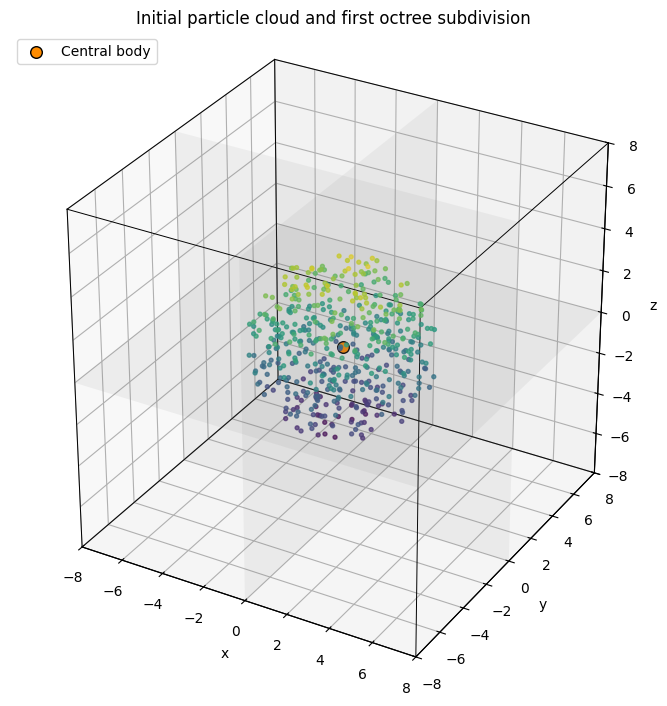

In [4]:
import numpy as np
import matplotlib.pyplot as plt

with open("nbody_3d_512.bin", "rb") as file:
    count = int(np.fromfile(file, dtype=np.uint64, count=1)[0])
    initial = np.fromfile(file, dtype=np.float64).reshape(count, 7)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")
points = ax.scatter(initial[1:, 0], initial[1:, 1], initial[1:, 2],
                    c=initial[1:, 2], cmap="viridis", s=8, alpha=0.75)
ax.scatter(initial[0, 0], initial[0, 1], initial[0, 2],
           color="darkorange", edgecolor="black", s=70, label="Central body")

# Show the root cube and its three first-level splitting planes.
lo, hi = -8.0, 8.0
for x in (lo, hi):
    for y in (lo, hi):
        ax.plot([x, x], [y, y], [lo, hi], color="black", linewidth=0.7)
for x in (lo, hi):
    for z in (lo, hi):
        ax.plot([x, x], [lo, hi], [z, z], color="black", linewidth=0.7)
for y in (lo, hi):
    for z in (lo, hi):
        ax.plot([lo, hi], [y, y], [z, z], color="black", linewidth=0.7)
xx, yy = np.meshgrid([lo, hi], [lo, hi])
ax.plot_surface(np.zeros_like(xx), yy, xx, color="gray", alpha=0.08)
ax.plot_surface(xx, np.zeros_like(xx), yy, color="gray", alpha=0.08)
ax.plot_surface(xx, yy, np.zeros_like(xx), color="gray", alpha=0.08)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_zlim(lo, hi)
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.set_title("Initial particle cloud and first octree subdivision")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 5. Save the simulation as a GIF

The CUDA program stores one position snapshot every ten integration steps. This cell reads those snapshots and saves `nbody_octree_animation.gif` as a standalone file rather than embedding the animation in the notebook.

In [5]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import FileLink, display

with open("trajectory_octree.bin", "rb") as file:
    n_bodies, n_frames = np.fromfile(file, dtype=np.uint64, count=2)
    trajectory = np.fromfile(file, dtype=np.float64).reshape(int(n_frames), int(n_bodies), 3)

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection="3d")
points = ax.scatter(trajectory[0, 1:, 0], trajectory[0, 1:, 1], trajectory[0, 1:, 2],
                    s=7, c=trajectory[0, 1:, 2], cmap="viridis", alpha=0.75)
central, = ax.plot([trajectory[0, 0, 0]], [trajectory[0, 0, 1]], [trajectory[0, 0, 2]],
                   marker="o", linestyle="", markersize=9, color="darkorange",
                   markeredgecolor="black", label="Central body")
ax.set_xlim(-5, 5); ax.set_ylim(-5, 5); ax.set_zlim(-5, 5)
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.legend(loc="upper left")

def update(frame):
    xyz = trajectory[frame]
    points._offsets3d = (xyz[1:, 0], xyz[1:, 1], xyz[1:, 2])
    central.set_data_3d([xyz[0, 0]], [xyz[0, 1]], [xyz[0, 2]])
    ax.set_title(f"CUDA Barnes-Hut N-body — frame {frame + 1}/{len(trajectory)}")
    return points, central

animation = FuncAnimation(fig, update, frames=len(trajectory), interval=60, blit=False)
animation_file = "nbody_octree_animation.gif"
animation.save(animation_file, writer=PillowWriter(fps=16), dpi=90)
plt.close(fig)
print(f"Saved {animation_file}")
display(FileLink(animation_file))


Saved nbody_octree_animation.gif


/content/nbody_octree_animation.gif

## 6. What to observe

The direct tiled force is the exact GPU reference for this softened model. Barnes–Hut replaces distant groups by their mass and center of mass, so its error should be interpreted alongside its time. The benchmark includes the cost of rebuilding the tree: this is essential for a moving N-body system. The octree is dense and fixed-depth to keep the CUDA data structure readable; adaptive trees can save memory but require more involved construction and traversal. The root bounds and the value of `theta` are problem choices, not universal constants.